# T2 — Limpieza y EDA EVA-Rendimientos

Limpieza reproducible con `src/clean.py` (decisiones y evidencia en `T2-limpieza-eda.md`). Fuente: EVA Colombia 2006–2025 (`2pnw-mmge` + `uejq-wxrr`, datos.gov.co).

## 1. Carga y limpieza

In [1]:
import json
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../src')))
from clean import clean_eva

df, log = clean_eva()
print(json.dumps(log, indent=2))
print('Filas limpias:', len(df), '| modelables:', log['target_modelable'])

{
  "raw_rows": 372800,
  "numeric_nulls_after_coerce": {
    "anio": 0,
    "area_sembrada_ha": 0,
    "area_cosechada_ha": 0,
    "produccion_t": 0,
    "rendimiento_t_ha": 3433
  },
  "inconsistentes_gt20pct": 3631,
  "target_no_modelable": 11478,
  "target_modelable": 361322,
  "rendimiento_p99": 85.0,
  "rendimiento_p995_cota": 113.30740000000223,
  "rows_capped": 1845,
  "cultivos_raros": 119,
  "rows_in_rare_cultivos": 3148,
  "distinct_cultivos_norm": 248,
  "ratio_gt_1pct": 2.7545600858369097
}
Filas limpias: 372800 | modelables: 361322


## 2. Distribución del target (rendimiento t/ha)

Ceros = cultivo perdido (definido en UPRA: área cosechada 0 → rendimiento 0). p99 = 85 t/ha; cota de winsorización (p99.5) medida en celda 1.

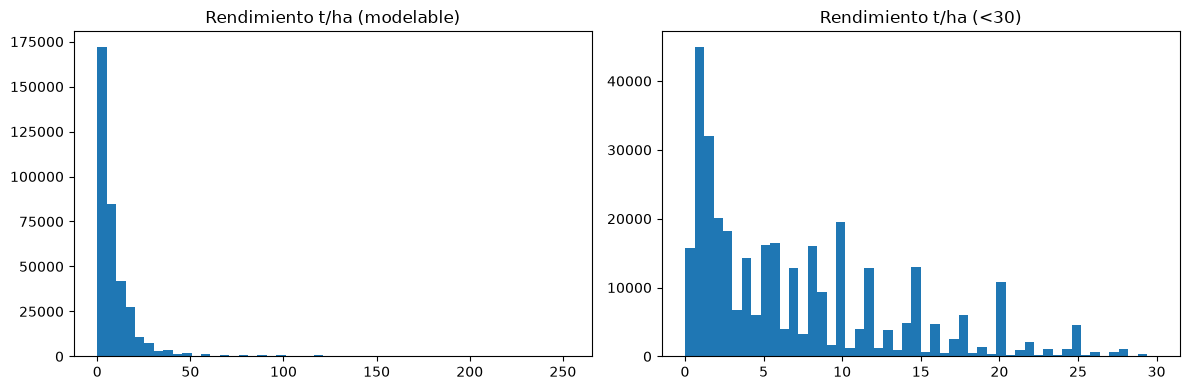

count    361322.000000
mean         10.018702
std          15.220426
min           0.020000
1%            0.400000
50%           6.000000
90%          20.000000
99%          85.000000
99.5%       113.307400
max         253.000000
ceros: 0.0 %


In [2]:
import matplotlib.pyplot as plt
r = df.loc[df.target_modelable, 'rendimiento_t_ha']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(r, bins=50)
ax[0].set_title('Rendimiento t/ha (modelable)')
ax[1].hist(r[r < 30], bins=50)
ax[1].set_title('Rendimiento t/ha (<30)')
plt.tight_layout(); plt.show()
print(r.describe(percentiles=[.01,.5,.9,.99,.995]).to_string())
print('ceros:', round((r == 0).mean()*100, 2), '%')

## 3. Cobertura temporal y cultivos principales

Constante: filtrar cultivos con <100 filas en T3/T4 (119 cultivos, 3.148 filas).

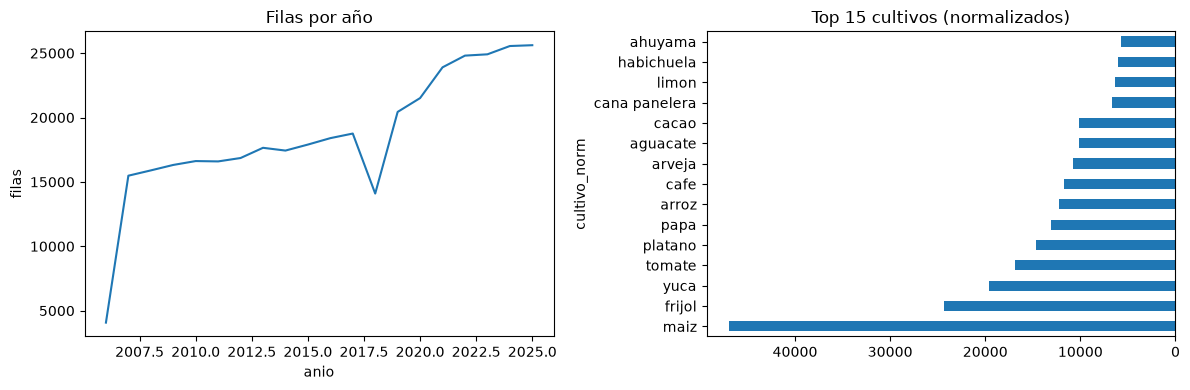

cultivos normalizados: 248 | municipios: 1109


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['anio'].value_counts().sort_index().plot(ax=ax[0])
ax[0].set_title('Filas por año'); ax[0].set_ylabel('filas')
df['cultivo_norm'].value_counts().head(15).plot.barh(ax=ax[1])
ax[1].set_title('Top 15 cultivos (normalizados)'); ax[1].invert_xaxis()
plt.tight_layout(); plt.show()
print('cultivos normalizados:', df.cultivo_norm.nunique(), '| municipios:', df.cod_mun.nunique())

## 4. Rendimiento por grupo de cultivo y por ciclo

La variabilidad entre grupos justifica target encoding por grupo/cultivo (decisión T3/T4).

In [4]:
g = (df[df.target_modelable]
     .groupby('grupo_norm')['rendimiento_clipped']
     .median().sort_values())
print(g.to_string())
print()
print(df.groupby('ciclo_norm')['rendimiento_clipped']
      .agg(['count', 'median', 'mean']).to_string())

grupo_norm
otros permanentes                                               1.05
cultivos tropicales tradicionales                               1.18
forestales                                                      1.20
leguminosas                                                     1.40
fibras                                                          1.58
cereales                                                        1.89
otros transitorios                                              2.00
oleaginosas                                                     3.00
hongos                                                          4.00
cultivos para condimentos, bebidas medicinales y aromaticas     4.00
plantas aromaticas, condimentarias y medicinales                4.20
flores y follajes                                               6.48
frutales                                                        9.00
tuberculos y platanos                                           9.00
raices y tuberculos    

## 5. Calidad: consistencia técnica y razón de cosecha

UPRA define producción = rendimiento × área cosechada. Filas con error relativo >20% se marcan `inconsistente` (3.631 filas, ~1%) y se revisan en T2 antes de modelar. Ratio cosechada/sembrada >1 en 2,75% (inconsistencia de reporte municipal).

In [5]:
print('inconsistentes:', int(df.inconsistente.sum()), '(', round(df.inconsistente.mean()*100, 2), '%)')
print('ratio>1:', round((df.ratio_cosecha > 1).mean()*100, 2), '%')
print('target no modelable:', int((~df.target_modelable).sum()))
print(df.groupby('fuente').size().to_string())

inconsistentes: 3631 ( 0.97 %)
ratio>1: 2.75 %
target no modelable: 11478
fuente
2pnw-mmge    206068
uejq-wxrr    166732


## Conclusiones T2

- 361.322 filas modelables (96,9% del total); 11.478 filas no modelables (área cosechada 0 o target nulo).
- Normalización de texto fusionó 388 cultivos crudos → 248 normalizados (MAIZ/Maíz).
- Winsorización en p99.5 (113,3 t/ha) afecta 1.845 filas; ceros conservados.
- 119 cultivos raros (<100 filas) con solo 3.148 filas → se filtran o agrupan por `grupo_norm` en T3.
- Siguiente paso (T3): features temporales (lags, rolling) + baselines con validación temporal.